In [8]:
import pandas as pd

dataset = pd.read_csv('/content/Sample - Superstore.csv', encoding='cp1252')

dataset.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [9]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [10]:
dataset.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [11]:
import matplotlib.pyplot as plt

In [12]:
import seaborn as sns

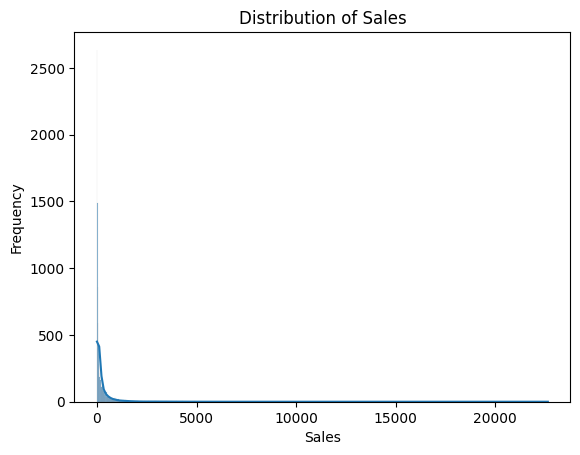

In [16]:
sns.histplot(data=dataset,x="Sales",kde='True' )

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [18]:
dataset["Sales"].skew()

np.float64(12.97275234181623)

Total sales of every January, feburary... across all years

In [24]:
print('mean:', dataset['Sales'].mean())
print('median:', dataset['Sales'].median())
print('standard deviation:', dataset['Sales'].std())
print('Skewness:', dataset['Sales'].skew())

mean: 229.85800083049833
median: 54.489999999999995
standard deviation: 623.2451005086818
Skewness: 12.97275234181623


**QUESTION 2**

<Axes: xlabel='Category', ylabel='Profit'>

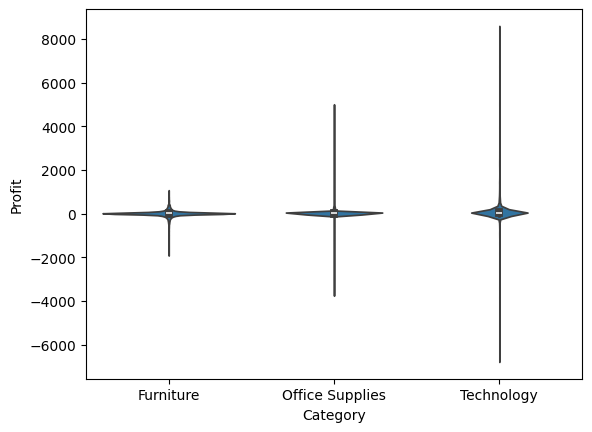

In [29]:
sns.violinplot(data=dataset, x='Category',y='Profit')

violin clearly shows the distribution's shape and density. The strip plot is better for seeing individual observations

<Axes: xlabel='Category', ylabel='Profit'>

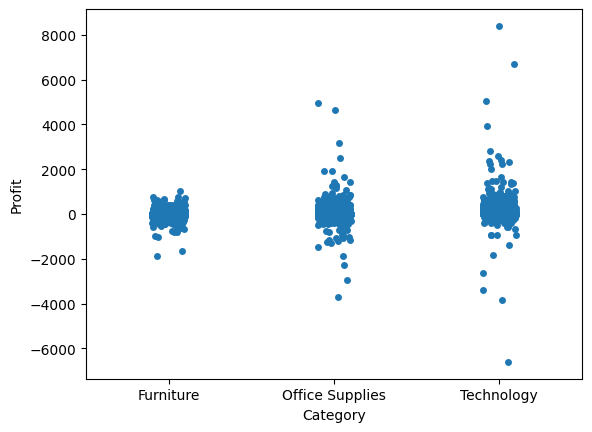

In [30]:
sns.stripplot(data=dataset, x='Category',y='Profit')

**QUESTION 3**

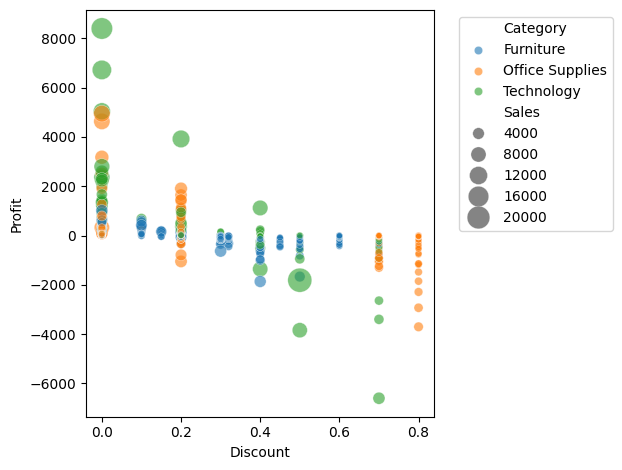

In [44]:
sns.scatterplot(data=dataset, x='Discount',y='Profit',hue='Category',size='Sales',sizes=(20,300) ,alpha=0.6)

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

**QUESTION 4**

In [46]:
numeric_data = dataset.select_dtypes(include="number")

In [47]:
pearson_corr = numeric_data.corr(method="pearson")

print("Pearson Correlation:")
print(pearson_corr)

Pearson Correlation:
               Row ID  Postal Code     Sales  Quantity  Discount    Profit
Row ID       1.000000     0.009671 -0.001359 -0.004016  0.013480  0.012497
Postal Code  0.009671     1.000000 -0.023854  0.012761  0.058443 -0.029961
Sales       -0.001359    -0.023854  1.000000  0.200795 -0.028190  0.479064
Quantity    -0.004016     0.012761  0.200795  1.000000  0.008623  0.066253
Discount     0.013480     0.058443 -0.028190  0.008623  1.000000 -0.219487
Profit       0.012497    -0.029961  0.479064  0.066253 -0.219487  1.000000


<Axes: >

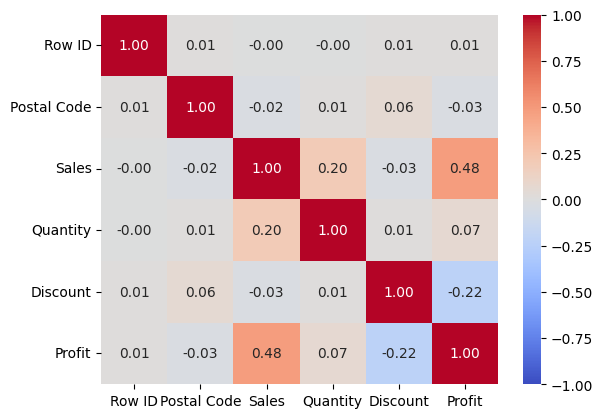

In [51]:
pearson_corr = numeric_data.corr(method="pearson")

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

In [48]:
spearman_corr = numeric_data.corr(method="spearman")

print("Spearman Correlation:")
print(spearman_corr)

Spearman Correlation:
               Row ID  Postal Code     Sales  Quantity  Discount    Profit
Row ID       1.000000     0.011466 -0.001310 -0.002416  0.012655 -0.010545
Postal Code  0.011466     1.000000 -0.002059  0.013952  0.052793 -0.005451
Sales       -0.001310    -0.002059  1.000000  0.327426 -0.056969  0.518407
Quantity    -0.002416     0.013952  0.327426  1.000000 -0.000878  0.234491
Discount     0.012655     0.052793 -0.056969 -0.000878  1.000000 -0.543350
Profit      -0.010545    -0.005451  0.518407  0.234491 -0.543350  1.000000


<Axes: >

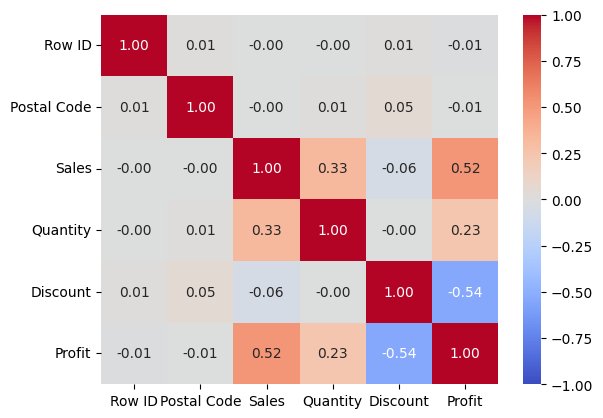

In [52]:
spearman_corr = numeric_data.corr(method="spearman")

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

In [49]:
difference = abs(pearson_corr - spearman_corr)

print(difference)

               Row ID  Postal Code     Sales  Quantity  Discount    Profit
Row ID       0.000000     0.001795  0.000049  0.001601  0.000826  0.023043
Postal Code  0.001795     0.000000  0.021795  0.001192  0.005650  0.024511
Sales        0.000049     0.021795  0.000000  0.126631  0.028778  0.039342
Quantity     0.001601     0.001192  0.126631  0.000000  0.009501  0.168238
Discount     0.000826     0.005650  0.028778  0.009501  0.000000  0.323863
Profit       0.023043     0.024511  0.039342  0.168238  0.323863  0.000000


<Axes: xlabel='Sales', ylabel='Profit'>

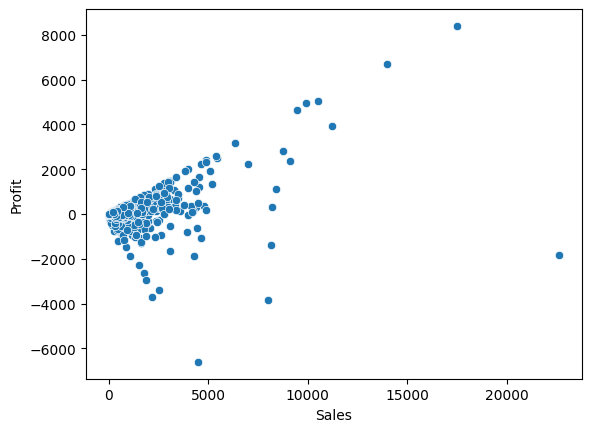

In [53]:
sns.scatterplot(data=dataset, x="Sales", y="Profit")

**QUESTION 5**

Category    Furniture  Office Supplies  Technology           All
Region                                                          
Central   163797.1638       167026.415  170416.312  5.012399e+05
East      208291.2040       205516.055  264973.981  6.787812e+05
South     117298.6840       125651.313  148771.908  3.917219e+05
West      252612.7435       220853.249  251991.832  7.254578e+05
All       741999.7953       719047.032  836154.033  2.297201e+06


Text(0.5, 1.0, 'Total Sales by Region and Category')

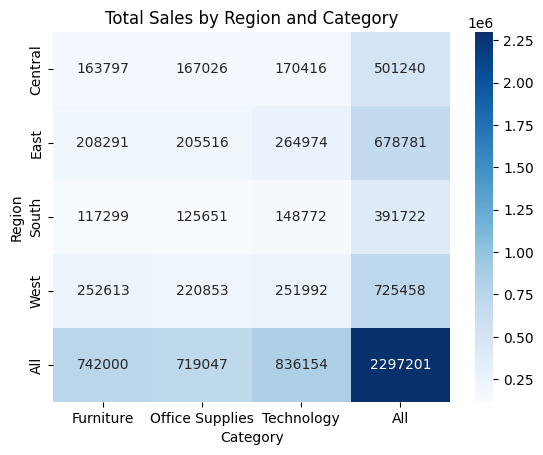

In [54]:
sales_pivot = pd.pivot_table(
    dataset,
    values="Sales",
    index="Region",
    columns="Category",
    aggfunc="sum",
    margins=True
)

print(sales_pivot)

sns.heatmap(
    sales_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Total Sales by Region and Category")

In [56]:
# highest Region × Category combination

region_category = sales_pivot.drop(index="All").drop(columns="All")

highest = region_category.stack().idxmax()
highest_value = region_category.stack().max()

print("Highest combination:", highest)
print("Total Sales:", highest_value)

Highest combination: ('East', 'Technology')
Total Sales: 264973.981


**QUESTION 5**

Text(0.5, 1.0, 'Monthly Sales with 3-Month Rolling Average')

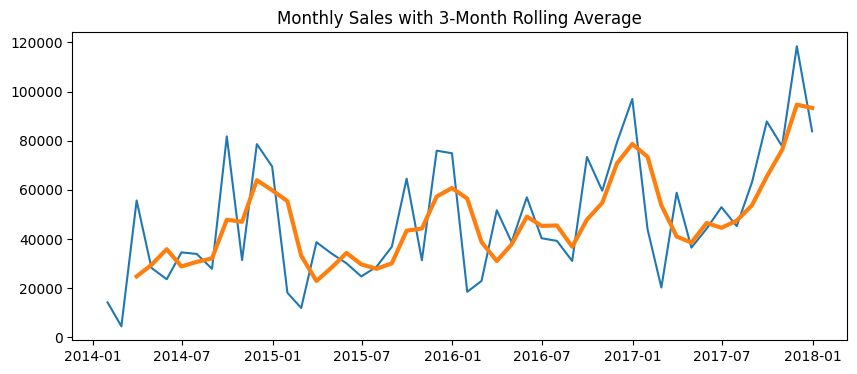

In [62]:
dataset["Order Date"] = pd.to_datetime(dataset["Order Date"])

monthly_sales = dataset.set_index("Order Date")["Sales"].resample("ME").sum()

rolling_sales = monthly_sales.rolling(3).mean()
plt.figure(figsize=(10, 4))
plt.plot(monthly_sales, label="Monthly Sales")
plt.plot(rolling_sales, label="3-Month Rolling Average", linewidth=3)


plt.title("Monthly Sales with 3-Month Rolling Average")

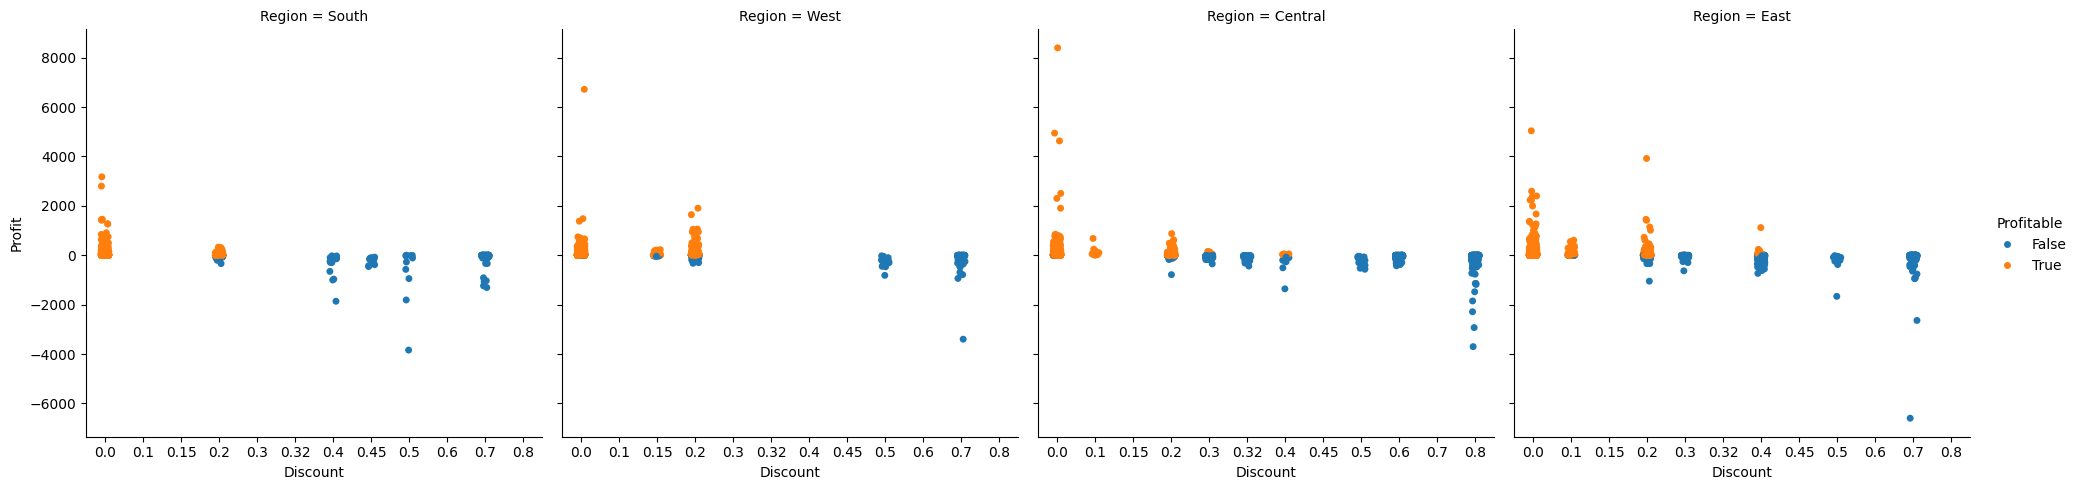

In [63]:
dataset["Profitable"] = dataset["Profit"] > 0

sns.catplot(
    data=dataset,
    x="Discount",
    y="Profit",
    col="Region",
    hue="Profitable",
    kind="strip",
    jitter=True,
    height=5,
    aspect=1
)

plt.show()

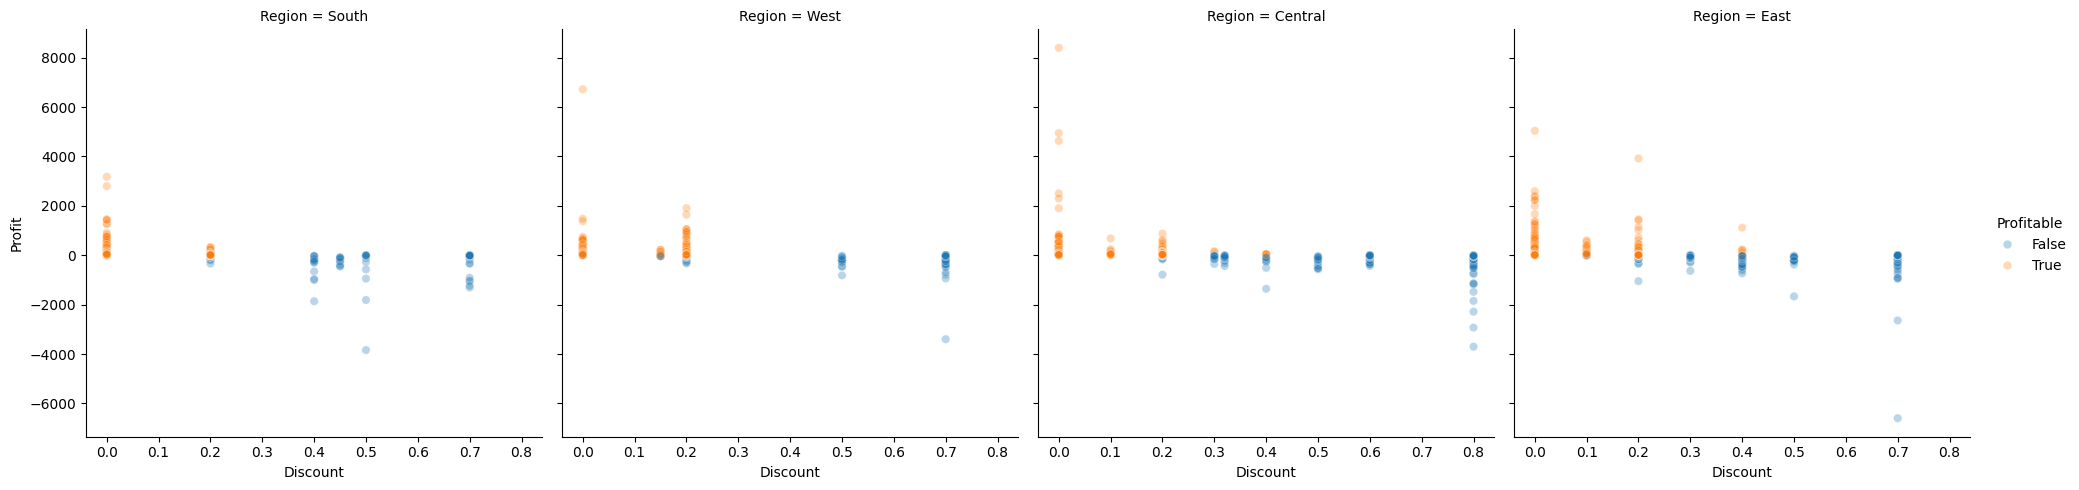

In [68]:
dataset["Profitable"] = dataset["Profit"] > 0

sns.relplot(
    data=dataset,
    x="Discount",
    y="Profit",
    col="Region",
    hue="Profitable",
    kind="scatter",
    alpha=0.3,
    height=5,
    aspect=1
)

plt.show()

Text(0.5, 1.0, 'Raw Discount vs Profit')

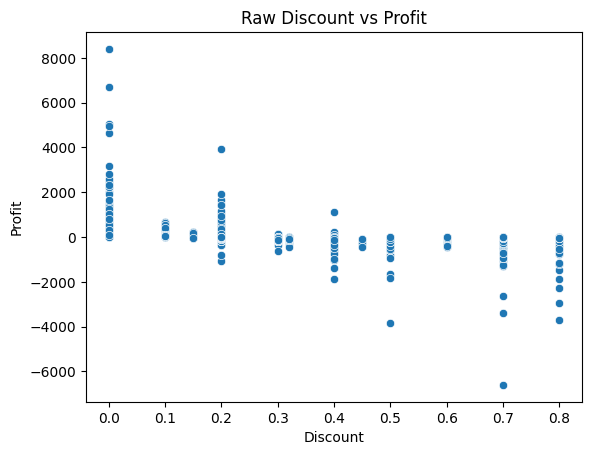

In [65]:
sns.scatterplot(
    data=dataset,
    x="Discount",
    y="Profit"
)

plt.title("Raw Discount vs Profit")

Fixed plot + annotate highest profit and largest loss

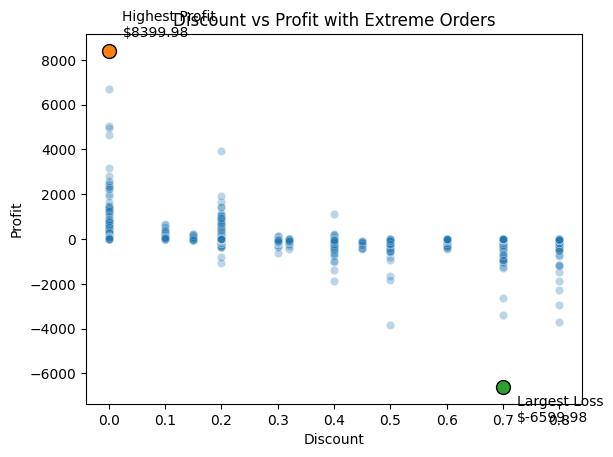

In [66]:

max_profit = dataset.loc[dataset["Profit"].idxmax()]
max_loss = dataset.loc[dataset["Profit"].idxmin()]

sns.scatterplot(
    data=dataset,
    x="Discount",
    y="Profit",
    alpha=0.3
)

plt.scatter(
    max_profit["Discount"],
    max_profit["Profit"],
    s=100,
    edgecolor="black"
)

plt.scatter(
    max_loss["Discount"],
    max_loss["Profit"],
    s=100,
    edgecolor="black"
)

plt.annotate(
    f"Highest Profit\n${max_profit['Profit']:.2f}",
    (max_profit["Discount"], max_profit["Profit"]),
    xytext=(10, 10),
    textcoords="offset points"
)

plt.annotate(
    f"Largest Loss\n${max_loss['Profit']:.2f}",
    (max_loss["Discount"], max_loss["Profit"]),
    xytext=(10, -25),
    textcoords="offset points"
)

plt.title("Discount vs Profit with Extreme Orders")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()